# Definitions


In [1]:
import os
import json
import numpy as np
import librosa
import pandas as pd
#import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix

In [2]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

In [3]:
# Final categories - Essential for interpreting the numeric indices
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices - Useful if you need to convert names to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

# Load Data

In [4]:
# Load pre-processed data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

Loaded data: (68879, 96, 130)



Class distribution in the complete dataset:
  other_percussion: 9085 samples (13.2%)
  electric_bass: 6781 samples (9.8%)
  drum_set: 6300 samples (9.1%)
  piano: 5604 samples (8.1%)
  other_bowed_strings: 4946 samples (7.2%)
  clean_electric_guitar: 4790 samples (7.0%)
  synthesizer: 4711 samples (6.8%)
  other_plucked_strings: 3635 samples (5.3%)
  fx_and_processed: 3452 samples (5.0%)
  male_vocals: 3180 samples (4.6%)
  violin: 3010 samples (4.4%)
  distorted_electric_guitar: 2475 samples (3.6%)
  acoustic_guitar: 2452 samples (3.6%)
  female_singer: 2190 samples (3.2%)
  woodwinds: 1860 samples (2.7%)
  vocalists: 1565 samples (2.3%)
  reed_instruments: 1460 samples (2.1%)
  brass: 1383 samples (2.0%)


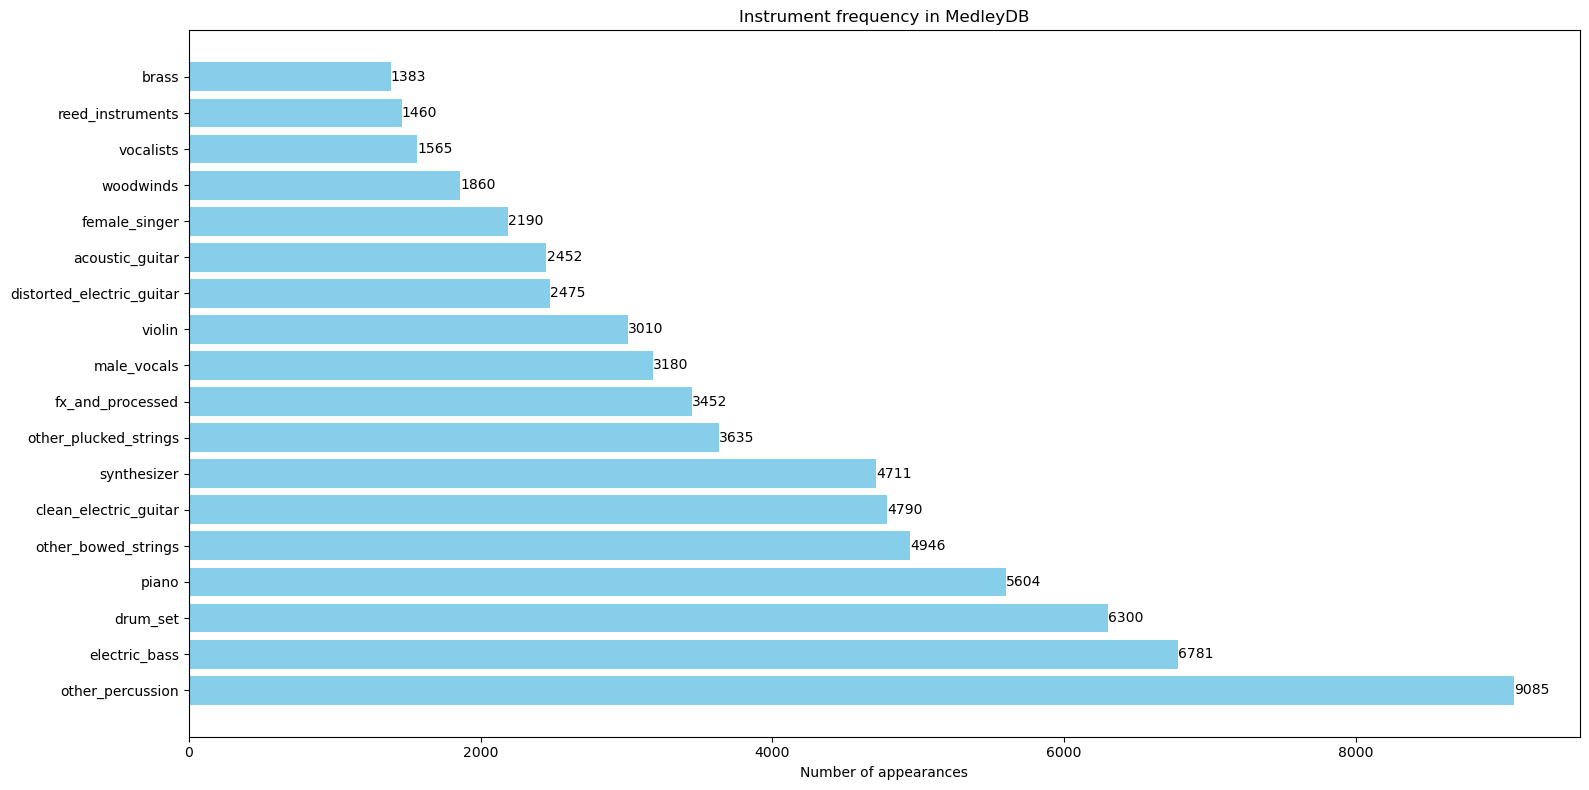


Dataset dimensions:
  Full data: (68879, 96, 130)
  Total number of samples: 68879
  Number of categories: 18


In [5]:
unique_classes, class_counts = np.unique(y, return_counts=True)

# Create a dictionary in the format {instrument: frequency}
instrument_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = instrument_categories[idx]
    instrument_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the complete dataset:")
for category, count in sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count/len(y)*100:.1f}%)")

plot_instrument_histogram(instrument_counts, top_n=len(instrument_categories))

print(f"\nDataset dimensions:")
print(f"  Full data: {X.shape}")
print(f"  Total number of samples: {len(y)}")
print(f"  Number of categories: {len(instrument_categories)}")

In [6]:
# Create inverse mapping from index to category name
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]
ordered_labels

['electric_bass',
 'drum_set',
 'piano',
 'synthesizer',
 'clean_electric_guitar',
 'distorted_electric_guitar',
 'acoustic_guitar',
 'violin',
 'female_singer',
 'vocalists',
 'male_vocals',
 'other_bowed_strings',
 'woodwinds',
 'brass',
 'other_percussion',
 'other_plucked_strings',
 'reed_instruments',
 'fx_and_processed']

# Model 1 (Biggest 32-64-128-128)

In [14]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 130, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 130, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 24576)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,145,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,241,746 (12.37 MB)

 Trainable params: 3,241,298 (12.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [22]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=100)

model_name = 'best_model_stem.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.3758 - loss: 2.2412
Epoch 1: val_accuracy improved from -inf to 0.63712, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 355s 205ms/step - accuracy: 0.3758 - loss: 2.2409 - val_accuracy: 0.6371 - val_loss: 1.0785
Epoch 2/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.6644 - loss: 1.0277
Epoch 2: val_accuracy improved from 0.63712 to 0.83631, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 354s 206ms/step - accuracy: 0.6644 - loss: 1.0276 - val_accuracy: 0.8363 - val_loss: 0.5343
Epoch 3/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.7734 - loss: 0.6897
Epoch 3: val_accuracy improved from 0.83631 to 0.86077, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 351s 204ms/step - accuracy: 0.7735 - loss: 0.6896 - val_accuracy: 0.8608 - val_loss: 0.4332
Epoch 4/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8202 - loss: 0.5405
Epoch 4: val_accuracy did not improve from 0.86077
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 351s 204ms/step - accuracy: 0.8202 - loss: 0.5405 - val_accuracy: 0.8015 - val_loss: 0.7552
Epoch 5/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8539 - loss: 0.4478
Epoch 5: val_accuracy improved from 0.86077 to 0.88727, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 352s 205ms/step - accuracy: 0.8539 - loss: 0.4478 - val_accuracy: 0.8873 - val_loss: 0.3885
Epoch 6/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.8707 - loss: 0.3980
Epoch 6: val_accuracy did not improve from 0.88727
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 350s 204ms/step - accuracy: 0.8707 - loss: 0.3980 - val_accuracy: 0.8803 - val_loss: 0.4235
Epoch 7/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8909 - loss: 0.3441
Epoch 7: val_accuracy improved from 0.88727 to 0.92313, saving model to best_model_stem.h5


...

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 362s 210ms/step - accuracy: 0.9663 - loss: 0.1031 - val_accuracy: 0.9604 - val_loss: 0.1664
Epoch 60/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9625 - loss: 0.1149
Epoch 60: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 359s 209ms/step - accuracy: 0.9625 - loss: 0.1149 - val_accuracy: 0.9581 - val_loss: 0.1897
Epoch 61/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9656 - loss: 0.1038
Epoch 61: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 362s 210ms/step - accuracy: 0.9656 - loss: 0.1038 - val_accuracy: 0.9541 - val_loss: 0.2167
Epoch 62/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9662 - loss: 0.1037
Epoch 62: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9662 - loss: 0.1037 - val_accuracy: 0.9308 - val_loss: 1.0977
Epoch 63/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 361s 210ms/step - accuracy: 0.9649 - loss: 0.1093 - val_accuracy: 0.9605 - val_loss: 0.1734
Epoch 65/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9654 - loss: 0.1076
Epoch 65: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9654 - loss: 0.1076 - val_accuracy: 0.9523 - val_loss: 0.2185
Epoch 66/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9670 - loss: 0.0990
Epoch 66: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9670 - loss: 0.0990 - val_accuracy: 0.9569 - val_loss: 0.2402
Epoch 67/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9629 - loss: 0.1127
Epoch 67: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 361s 210ms/step - accuracy: 0.9629 - loss: 0.1127 - val_accuracy: 0.9548 - val_loss: 0.2551
Epoch 68/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 374s 217ms/step - accuracy: 0.9676 - loss: 0.1008 - val_accuracy: 0.9609 - val_loss: 0.2507
Epoch 93/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9673 - loss: 0.1065
Epoch 93: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 364s 212ms/step - accuracy: 0.9673 - loss: 0.1065 - val_accuracy: 0.9584 - val_loss: 0.1800
Epoch 94/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9680 - loss: 0.1016
Epoch 94: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 365s 212ms/step - accuracy: 0.9680 - loss: 0.1016 - val_accuracy: 0.7279 - val_loss: 6.3730
Epoch 95/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9660 - loss: 0.1049
Epoch 95: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 365s 212ms/step - accuracy: 0.9660 - loss: 0.1049 - val_accuracy: 0.9440 - val_loss: 0.2894
Epoch 96/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 371s 216ms/step - accuracy: 0.9679 - loss: 0.1074 - val_accuracy: 0.9611 - val_loss: 0.2034
Epoch 105/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9685 - loss: 0.0998
Epoch 105: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 366s 213ms/step - accuracy: 0.9685 - loss: 0.0998 - val_accuracy: 0.8587 - val_loss: 4.2234
Epoch 106/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9672 - loss: 0.1056
Epoch 106: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 367s 213ms/step - accuracy: 0.9672 - loss: 0.1056 - val_accuracy: 0.9525 - val_loss: 0.3648
Epoch 107/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.9675 - loss: 0.1076
Epoch 107: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 368s 214ms/step - accuracy: 0.9675 - loss: 0.1076 - val_accuracy: 0.9570 - val_loss: 0.2007
Epoch 108/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accur

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 385s 224ms/step - accuracy: 0.9686 - loss: 0.0985 - val_accuracy: 0.9624 - val_loss: 0.2404


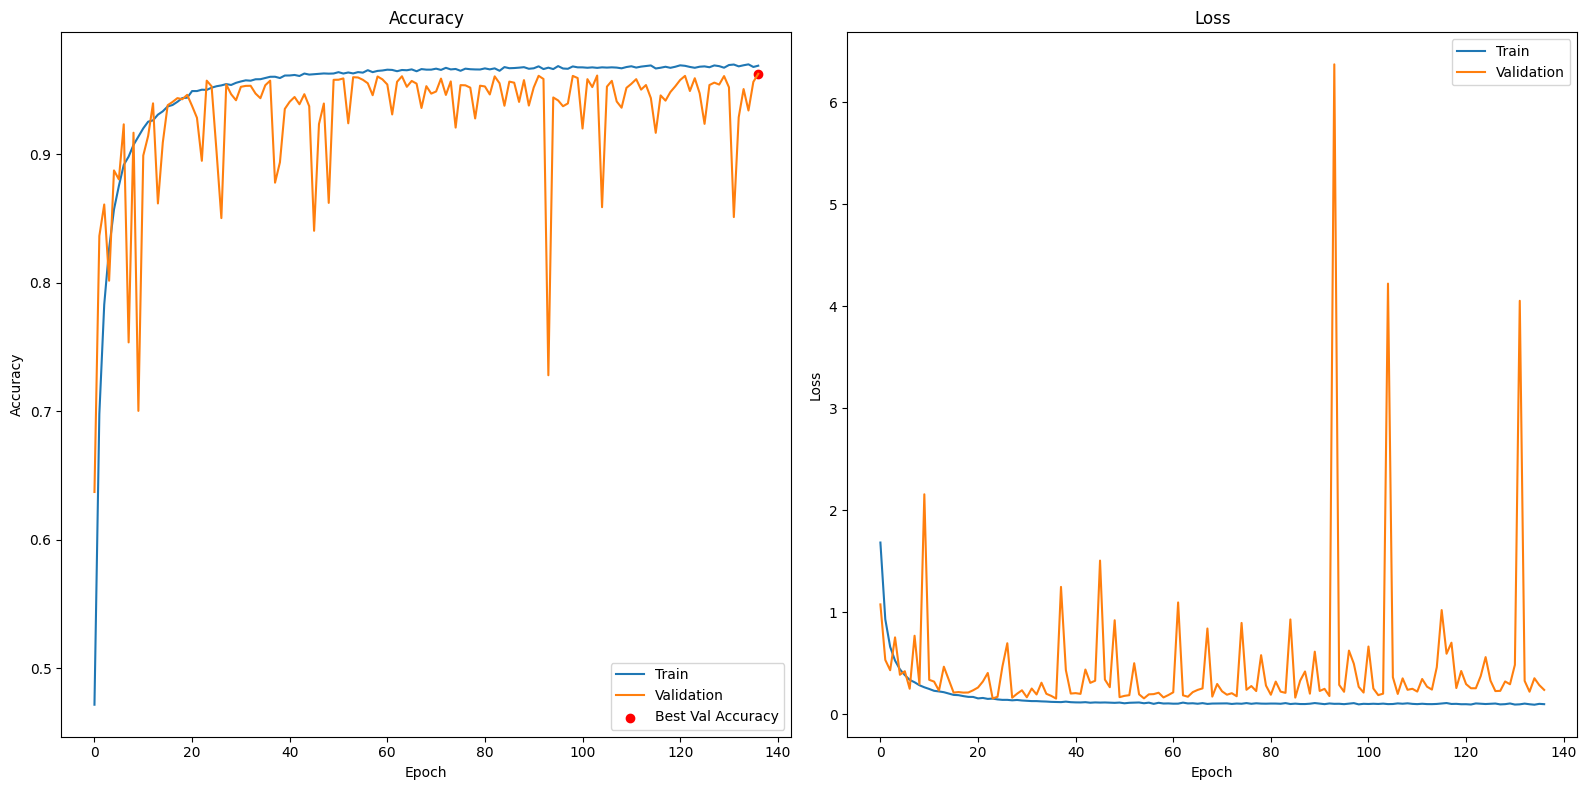

In [15]:
# History plot
log_df = pd.read_csv('training_model_stem.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
model.load_weights('best_model_stem.h5')

388/388 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step
216/216 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step


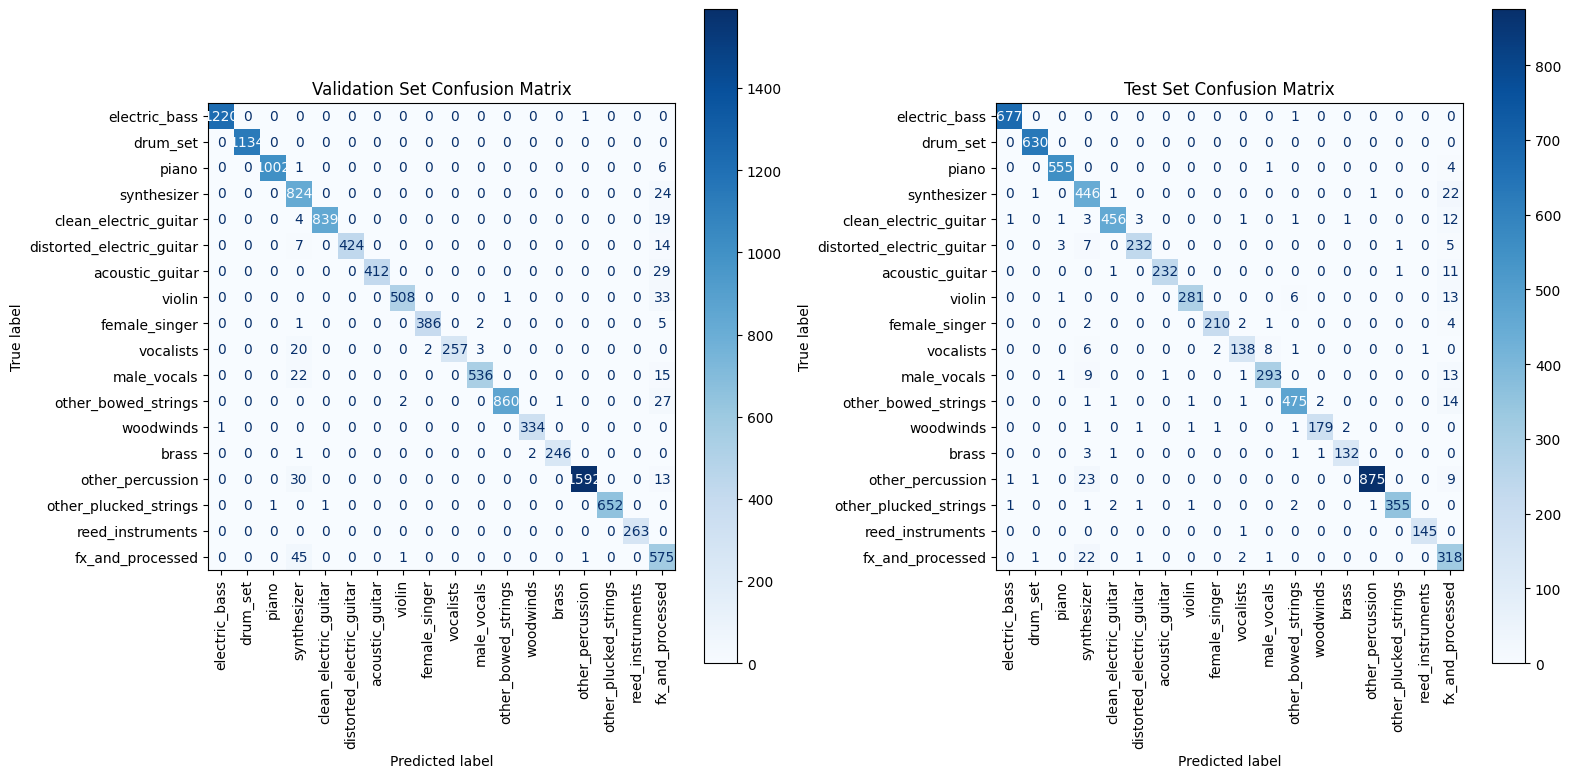

In [17]:
# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Get ordered category labels
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Plot
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")

plt.tight_layout()
plt.show()


In [18]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1221
           1       1.00      1.00      1.00      1134
           2       1.00      0.99      1.00      1009
           3       0.86      0.97      0.91       848
           4       1.00      0.97      0.99       862
           5       1.00      0.95      0.98       445
           6       1.00      0.93      0.97       441
           7       0.99      0.94      0.96       542
           8       0.99      0.98      0.99       394
           9       1.00      0.91      0.95       282
          10       0.99      0.94      0.96       573
          11       1.00      0.97      0.98       890
          12       0.99      1.00      1.00       335
          13       1.00      0.99      0.99       249
          14       1.00      0.97      0.99      1635
          15       1.00      1.00      1.00       654
          16       1.00      1.00      1.00       263
          17       0.76    

# Model 2, reduced size (16-32-64-64)

Data it's now normalized (wasn't before)

In [7]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    #X_filtered, y_filtered, test_size=0.1, random_state=42, stratify=y_filtered
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

#print(f"Loaded data: {X_filtered.shape}")
print(f"Loaded data: {X.shape}")

Loaded data: (68879, 96, 130)


In [8]:
# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

#We normalize everything based on this
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

In [9]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 130, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 130, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       786,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 811,410 (3.10 MB)

 Trainable params: 811,186 (3.09 MB)

 Non-trainable params: 224 (896.00 B)

In [10]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_small_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_stem_small_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.3843 - loss: 2.0389
Epoch 1: val_accuracy improved from -inf to 0.71874, saving model to best_model_stem_small_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 139s 85ms/step - accuracy: 0.3845 - loss: 2.0384 - val_accuracy: 0.7187 - val_loss: 0.8766
Epoch 2/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.6497 - loss: 1.0646
Epoch 2: val_accuracy improved from 0.71874 to 0.81407, saving model to best_model_stem_small_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 83ms/step - accuracy: 0.6497 - loss: 1.0645 - val_accuracy: 0.8141 - val_loss: 0.6037
Epoch 3/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7346 - loss: 0.8062
Epoch 3: val_accuracy improved from 0.81407 to 0.84050, saving model to best_model_stem_small_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 134s 83ms/step - accuracy: 0.7346 - loss: 0.8061 - val_accuracy: 0.8405 - val_loss: 0.5769
Epoch 4/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7891 - loss: 0.6441
Epoch 4: val_accuracy improved from 0.84050 to 0.88695, saving model to best_model_stem_small_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.7891 - loss: 0.6440 - val_accuracy: 0.8870 - val_loss: 0.3723
Epoch 5/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8337 - loss: 0.4980
Epoch 5: val_accuracy did not improve from 0.88695
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 134s 83ms/step - accuracy: 0.8337 - loss: 0.4980 - val_accuracy: 0.8773 - val_loss: 0.4340
Epoch 6/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8593 - loss: 0.4244
Epoch 6: val_accuracy improved from 0.88695 to 0.91289, saving model to best_model_stem_small_cqt.h5


...

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9532 - loss: 0.1424 - val_accuracy: 0.9494 - val_loss: 0.1852
Epoch 29/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9540 - loss: 0.1402
Epoch 29: val_accuracy did not improve from 0.94938
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9540 - loss: 0.1402 - val_accuracy: 0.9445 - val_loss: 0.2157
Epoch 30/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9514 - loss: 0.1450
Epoch 30: val_accuracy did not improve from 0.94938
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 83ms/step - accuracy: 0.9514 - loss: 0.1450 - val_accuracy: 0.9458 - val_loss: 0.1957
Epoch 31/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9550 - loss: 0.1339
Epoch 31: val_accuracy did not improve from 0.94938
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9550 - loss: 0.1339 - val_accuracy: 0.9458 - val_loss: 0.2056
Epoch 32/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9539 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9560 - loss: 0.1337 - val_accuracy: 0.9504 - val_loss: 0.1838
Epoch 34/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9572 - loss: 0.1278
Epoch 34: val_accuracy did not improve from 0.95045
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9572 - loss: 0.1278 - val_accuracy: 0.9492 - val_loss: 0.1911
Epoch 35/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9546 - loss: 0.1386
Epoch 35: val_accuracy did not improve from 0.95045
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9546 - loss: 0.1386 - val_accuracy: 0.9488 - val_loss: 0.1865
Epoch 36/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9585 - loss: 0.1229
Epoch 36: val_accuracy did not improve from 0.95045
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9585 - loss: 0.1229 - val_accuracy: 0.9488 - val_loss: 0.1981
Epoch 37/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9572 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9580 - loss: 0.1265 - val_accuracy: 0.9522 - val_loss: 0.1774
Epoch 40/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9603 - loss: 0.1156
Epoch 40: val_accuracy did not improve from 0.95219
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9603 - loss: 0.1156 - val_accuracy: 0.9487 - val_loss: 0.2017
Epoch 41/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9612 - loss: 0.1184
Epoch 41: val_accuracy did not improve from 0.95219
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9612 - loss: 0.1184 - val_accuracy: 0.9484 - val_loss: 0.2056
Epoch 42/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9583 - loss: 0.1229
Epoch 42: val_accuracy did not improve from 0.95219
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9583 - loss: 0.1229 - val_accuracy: 0.9473 - val_loss: 0.2093
Epoch 43/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9590 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9603 - loss: 0.1165 - val_accuracy: 0.9538 - val_loss: 0.1858
Epoch 46/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9599 - loss: 0.1172
Epoch 46: val_accuracy did not improve from 0.95383
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9599 - loss: 0.1172 - val_accuracy: 0.9494 - val_loss: 0.2118
Epoch 47/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9602 - loss: 0.1184
Epoch 47: val_accuracy did not improve from 0.95383
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9602 - loss: 0.1184 - val_accuracy: 0.9445 - val_loss: 0.1945
Epoch 48/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9600 - loss: 0.1181
Epoch 48: val_accuracy did not improve from 0.95383
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9600 - loss: 0.1181 - val_accuracy: 0.9499 - val_loss: 0.1900
Epoch 49/300
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9586 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 144s 89ms/step - accuracy: 0.9662 - loss: 0.1008 - val_accuracy: 0.9559 - val_loss: 0.2173


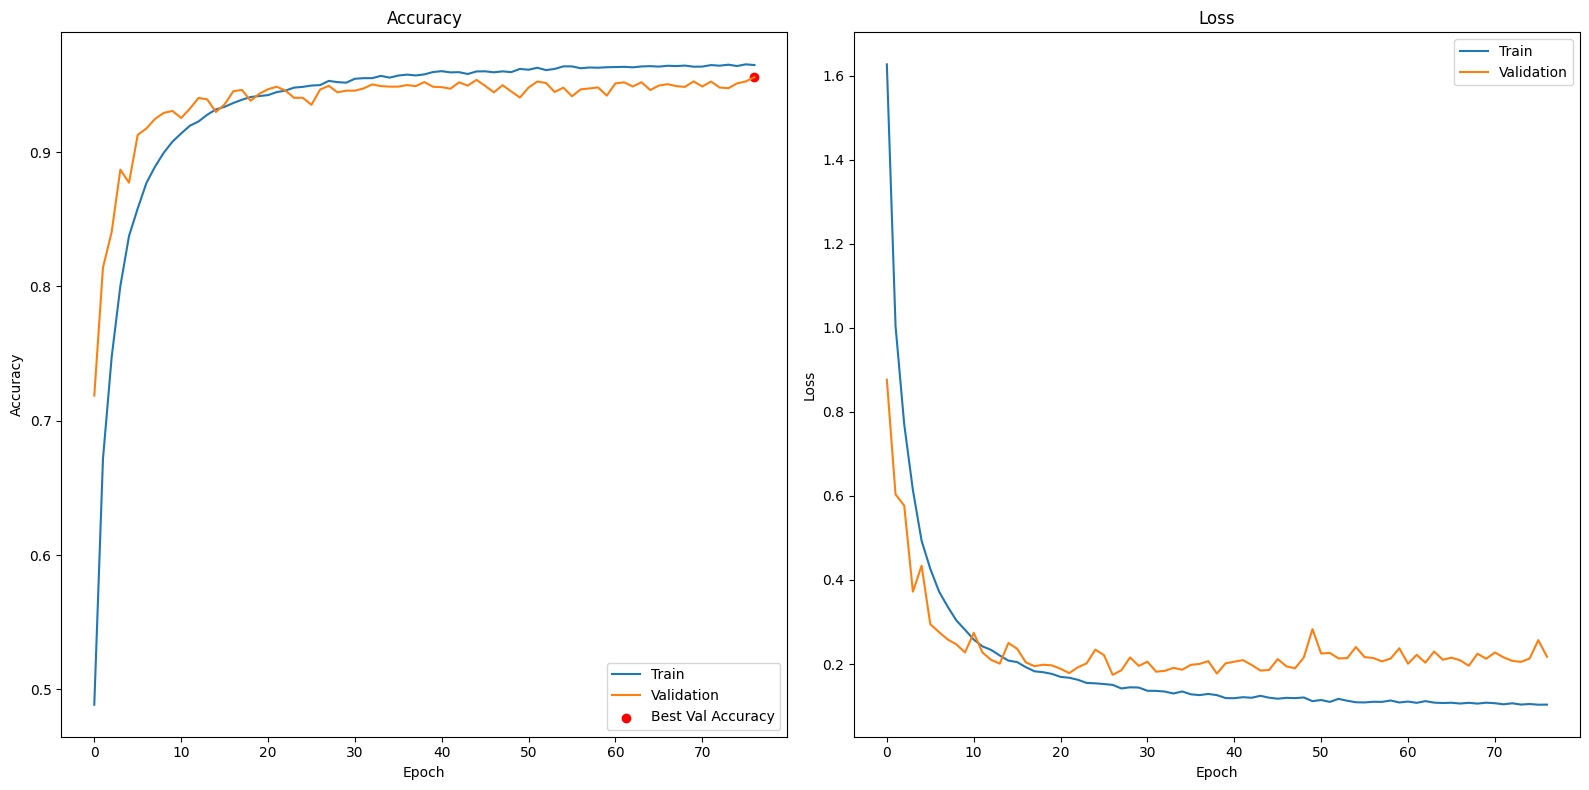

In [11]:
# History plot
log_df = pd.read_csv('training_model_stem_small_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
model.load_weights('best_model_stem_small_cqt.h5')

323/323 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
216/216 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


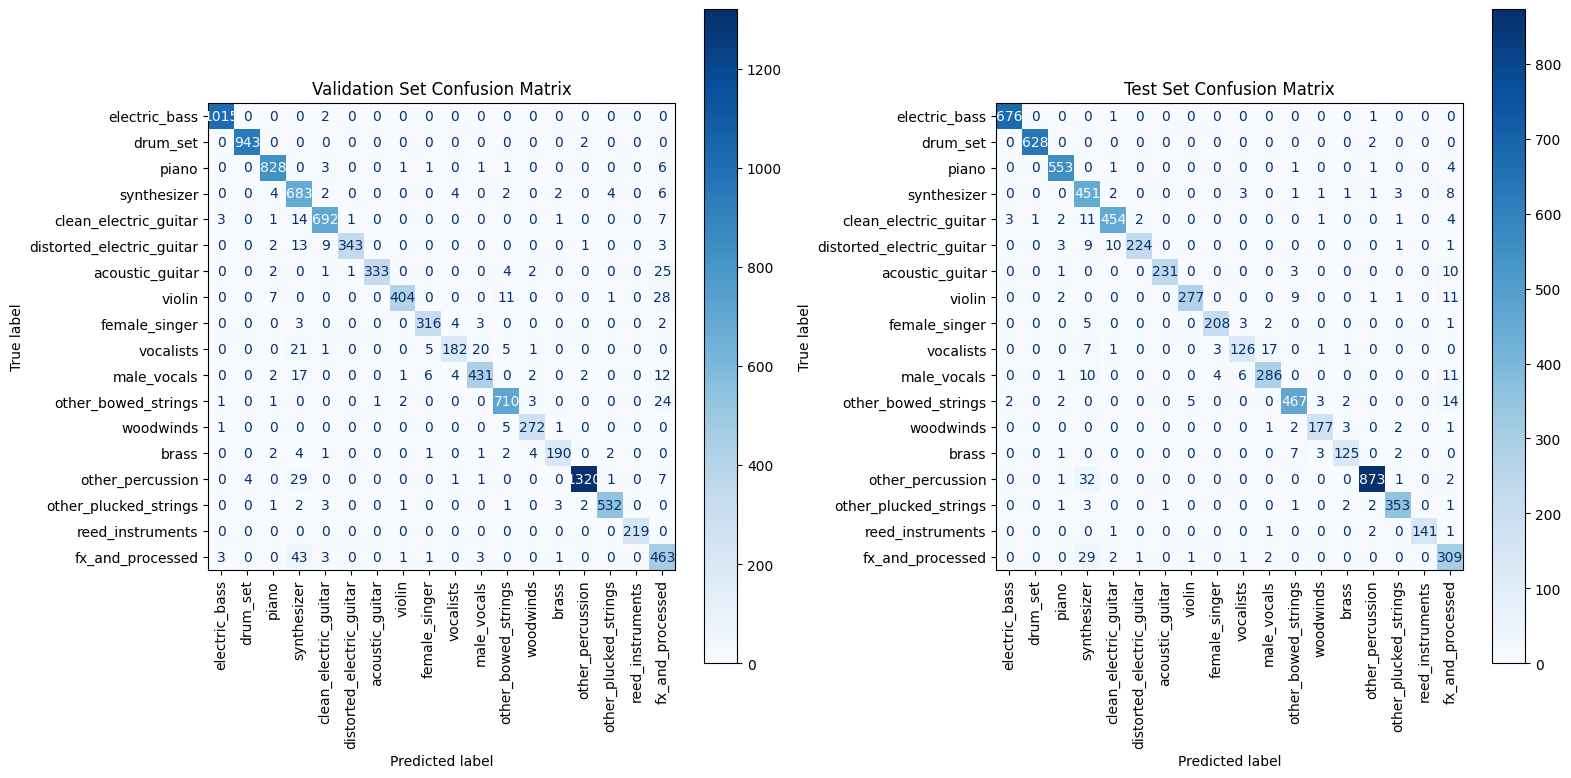

In [13]:
# Predict class probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Worse for other percusion, losses the abbility of classifying them properly.
Also vocalist have problems. Makes sense as it's only chorus or polyphonies, but still close to isolated male or female voice.

In [14]:
# For classification report
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.99      1.00      1.00      1017
                 drum_set       1.00      1.00      1.00       945
                    piano       0.97      0.98      0.98       841
              synthesizer       0.82      0.97      0.89       707
    clean_electric_guitar       0.97      0.96      0.96       719
distorted_electric_guitar       0.99      0.92      0.96       371
          acoustic_guitar       1.00      0.90      0.95       368
                   violin       0.99      0.90      0.94       451
            female_singer       0.96      0.96      0.96       328
                vocalists       0.93      0.77      0.85       235
              male_vocals       0.94      0.90      0.92       477
      other_bowed_strings       0.96      0.96      0.96       742
                woodwinds       0.96      0.97      0.97       279
                    brass       0.96      0.92      0.94     

# Model 3, reducing output layer to 32

We can consider if it's worth keeping vocalist and other drums after this model.

In [15]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax') 
])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 96, 130, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 96, 130, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 48, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       393,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 18)             │           594 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 417,586 (1.59 MB)

 Trainable params: 417,362 (1.59 MB)

 Non-trainable params: 224 (896.00 B)

In [16]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_smaller_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_smaller_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.2946 - loss: 2.2254
Epoch 1: val_accuracy improved from -inf to 0.55468, saving model to best_model_stem_smaller_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 82ms/step - accuracy: 0.2947 - loss: 2.2251 - val_accuracy: 0.5547 - val_loss: 1.3617
Epoch 2/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.4856 - loss: 1.5657
Epoch 2: val_accuracy improved from 0.55468 to 0.66047, saving model to best_model_stem_smaller_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 131s 81ms/step - accuracy: 0.4856 - loss: 1.5656 - val_accuracy: 0.6605 - val_loss: 1.0548
Epoch 3/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.5865 - loss: 1.2516
Epoch 3: val_accuracy improved from 0.66047 to 0.74177, saving model to best_model_stem_smaller_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 132s 82ms/step - accuracy: 0.5865 - loss: 1.2515 - val_accuracy: 0.7418 - val_loss: 0.7709
Epoch 4/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6508 - loss: 1.0271
Epoch 4: val_accuracy improved from 0.74177 to 0.76781, saving model to best_model_stem_smaller_cqt.h5


1615/1615 ━━━━━━━━━━━━━━━━━━━━ 131s 81ms/step - accuracy: 0.6508 - loss: 1.0271 - val_accuracy: 0.7678 - val_loss: 0.7204
Epoch 5/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.6960 - loss: 0.8998
Epoch 5: val_accuracy improved from 0.76781 to 0.81562, saving model to best_model_stem_smaller_cqt.h5


...

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9519 - loss: 0.1438 - val_accuracy: 0.9466 - val_loss: 0.2123
Epoch 71/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9549 - loss: 0.1386
Epoch 71: val_accuracy did not improve from 0.94657
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 83ms/step - accuracy: 0.9549 - loss: 0.1386 - val_accuracy: 0.9452 - val_loss: 0.2223
Epoch 72/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9566 - loss: 0.1337
Epoch 72: val_accuracy did not improve from 0.94657
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9566 - loss: 0.1337 - val_accuracy: 0.9433 - val_loss: 0.2175
Epoch 73/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9518 - loss: 0.1443
Epoch 73: val_accuracy did not improve from 0.94657
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 140s 82ms/step - accuracy: 0.9518 - loss: 0.1443 - val_accuracy: 0.9451 - val_loss: 0.2323
Epoch 74/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9569 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 137s 85ms/step - accuracy: 0.9565 - loss: 0.1307 - val_accuracy: 0.9473 - val_loss: 0.2201
Epoch 88/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9579 - loss: 0.1255
Epoch 88: val_accuracy did not improve from 0.94725
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 82ms/step - accuracy: 0.9579 - loss: 0.1255 - val_accuracy: 0.9421 - val_loss: 0.2297
Epoch 89/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9590 - loss: 0.1214
Epoch 89: val_accuracy did not improve from 0.94725
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 82ms/step - accuracy: 0.9590 - loss: 0.1214 - val_accuracy: 0.9455 - val_loss: 0.2439
Epoch 90/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9593 - loss: 0.1214
Epoch 90: val_accuracy did not improve from 0.94725
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 82ms/step - accuracy: 0.9593 - loss: 0.1214 - val_accuracy: 0.9413 - val_loss: 0.2522
Epoch 91/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9575 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 82ms/step - accuracy: 0.9575 - loss: 0.1277 - val_accuracy: 0.9481 - val_loss: 0.2248
Epoch 92/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9564 - loss: 0.1286
Epoch 92: val_accuracy did not improve from 0.94812
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 133s 82ms/step - accuracy: 0.9564 - loss: 0.1286 - val_accuracy: 0.9411 - val_loss: 0.2575
Epoch 93/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9566 - loss: 0.1271
Epoch 93: val_accuracy did not improve from 0.94812
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 83ms/step - accuracy: 0.9566 - loss: 0.1271 - val_accuracy: 0.9420 - val_loss: 0.2586
Epoch 94/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9591 - loss: 0.1224
Epoch 94: val_accuracy did not improve from 0.94812
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9591 - loss: 0.1224 - val_accuracy: 0.9453 - val_loss: 0.2226
Epoch 95/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9590 - loss:

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 138s 85ms/step - accuracy: 0.9622 - loss: 0.1091 - val_accuracy: 0.9485 - val_loss: 0.2198
Epoch 109/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9594 - loss: 0.1199
Epoch 109: val_accuracy did not improve from 0.94851
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 134s 83ms/step - accuracy: 0.9594 - loss: 0.1199 - val_accuracy: 0.9444 - val_loss: 0.2421
Epoch 110/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9618 - loss: 0.1124
Epoch 110: val_accuracy did not improve from 0.94851
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 134s 83ms/step - accuracy: 0.9618 - loss: 0.1124 - val_accuracy: 0.9388 - val_loss: 0.2584
Epoch 111/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9603 - loss: 0.1179
Epoch 111: val_accuracy did not improve from 0.94851
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 135s 84ms/step - accuracy: 0.9603 - loss: 0.1179 - val_accuracy: 0.9433 - val_loss: 0.2619
Epoch 112/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9623 

1615/1615 ━━━━━━━━━━━━━━━━━━━━ 140s 87ms/step - accuracy: 0.9635 - loss: 0.1077 - val_accuracy: 0.9501 - val_loss: 0.2408
Epoch 127/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9620 - loss: 0.1112
Epoch 127: val_accuracy did not improve from 0.95006
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9620 - loss: 0.1112 - val_accuracy: 0.9493 - val_loss: 0.2524
Epoch 128/500
1614/1615 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9618 - loss: 0.1083
Epoch 128: val_accuracy did not improve from 0.95006
1615/1615 ━━━━━━━━━━━━━━━━━━━━ 136s 84ms/step - accuracy: 0.9618 - loss: 0.1083 - val_accuracy: 0.9470 - val_loss: 0.2500


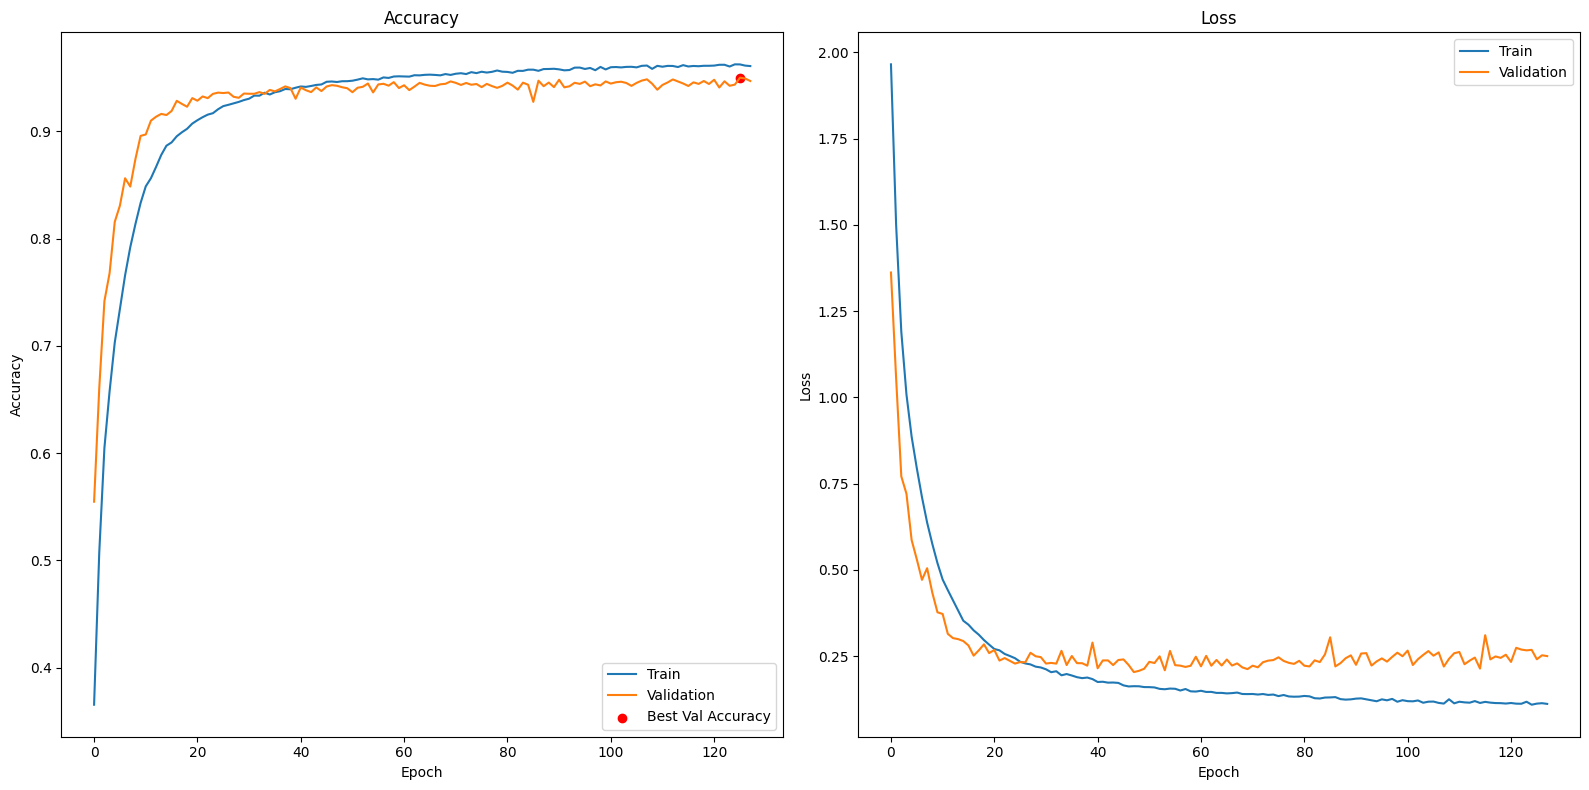

In [17]:
# History plot
log_df = pd.read_csv('training_model_stem_smaller_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

323/323 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
216/216 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step


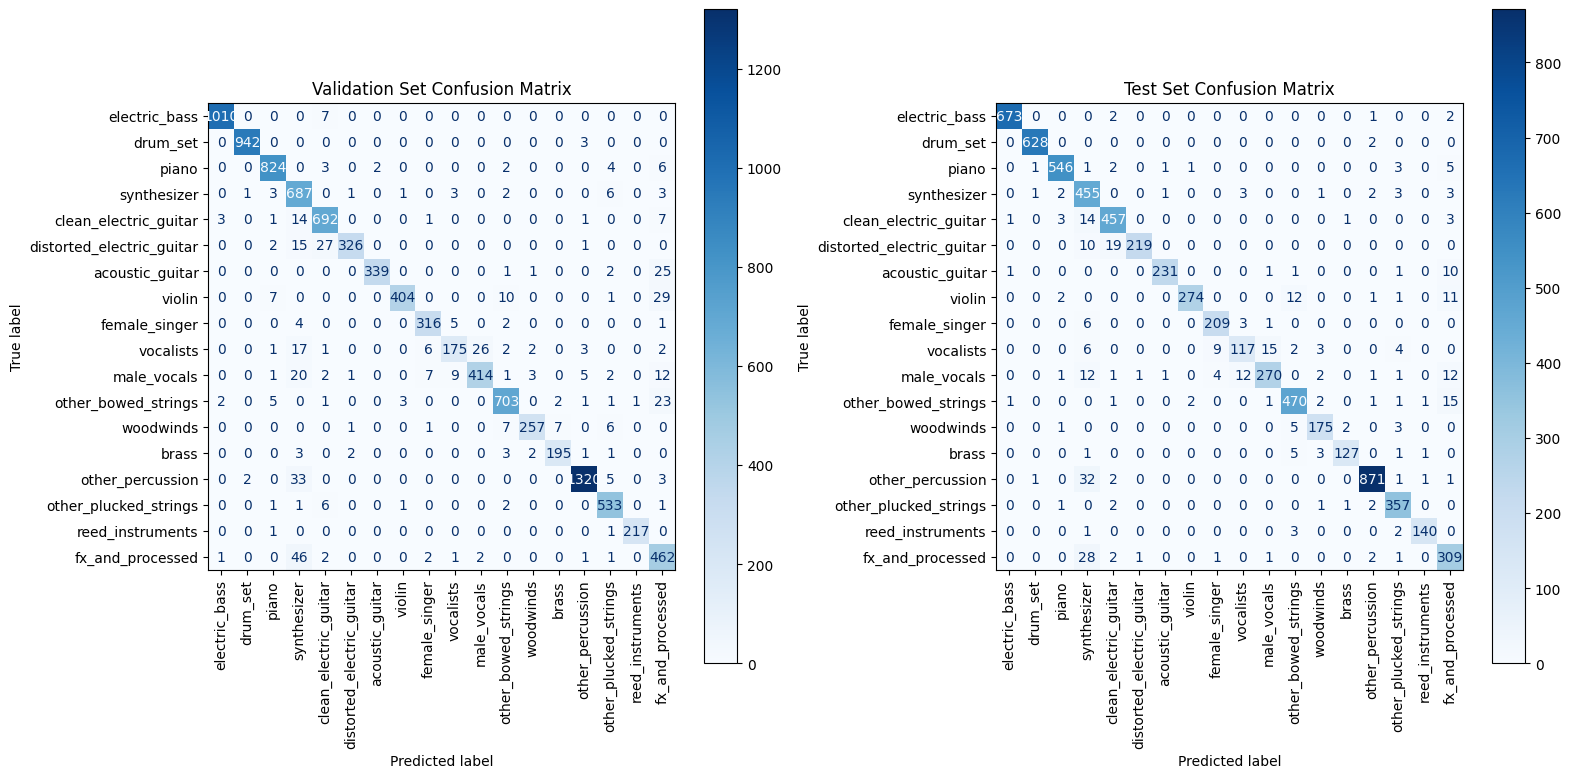

In [18]:
model.load_weights('best_model_stem_smaller_cqt.h5')
# Predict class probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
# For classification report
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.99      0.99      0.99      1017
                 drum_set       1.00      1.00      1.00       945
                    piano       0.97      0.98      0.98       841
              synthesizer       0.82      0.97      0.89       707
    clean_electric_guitar       0.93      0.96      0.95       719
distorted_electric_guitar       0.98      0.88      0.93       371
          acoustic_guitar       0.99      0.92      0.96       368
                   violin       0.99      0.90      0.94       451
            female_singer       0.95      0.96      0.96       328
                vocalists       0.91      0.74      0.82       235
              male_vocals       0.94      0.87      0.90       477
      other_bowed_strings       0.96      0.95      0.95       742
                woodwinds       0.97      0.92      0.94       279
                    brass       0.96      0.94      0.95     

# Model 4 Replace Flatten with GlobalAveragePooling2D

In [7]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # TO COMMENT
    #layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    #layers.BatchNormalization(),
    #layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')  
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128       
 hNormalization)                                                 
                                                        

In [13]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_GAP_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_GAP_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.3436 - loss: 2.0850
Epoch 1: val_accuracy improved from -inf to 0.54658, saving model to best_model_stem_GAP_cqt.h5


1550/1550 ━━━━━━━━━━━━━━━━━━━━ 152s 97ms/step - accuracy: 0.3436 - loss: 2.0848 - val_accuracy: 0.5466 - val_loss: 1.4068
Epoch 2/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5501 - loss: 1.3926
Epoch 2: val_accuracy did not improve from 0.54658
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 149s 96ms/step - accuracy: 0.5501 - loss: 1.3926 - val_accuracy: 0.5217 - val_loss: 1.3976
Epoch 3/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.6315 - loss: 1.1305
Epoch 3: val_accuracy improved from 0.54658 to 0.59706, saving model to best_model_stem_GAP_cqt.h5


1550/1550 ━━━━━━━━━━━━━━━━━━━━ 148s 96ms/step - accuracy: 0.6315 - loss: 1.1305 - val_accuracy: 0.5971 - val_loss: 1.1969
Epoch 4/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.6723 - loss: 0.9964
Epoch 4: val_accuracy improved from 0.59706 to 0.62682, saving model to best_model_stem_GAP_cqt.h5


1550/1550 ━━━━━━━━━━━━━━━━━━━━ 145s 94ms/step - accuracy: 0.6723 - loss: 0.9964 - val_accuracy: 0.6268 - val_loss: 1.1345
Epoch 5/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.6964 - loss: 0.9268
Epoch 5: val_accuracy improved from 0.62682 to 0.72466, saving model to best_model_stem_GAP_cqt.h5


1550/1550 ━━━━━━━━━━━━━━━━━━━━ 141s 91ms/step - accuracy: 0.6964 - loss: 0.9268 - val_accuracy: 0.7247 - val_loss: 0.8240
Epoch 6/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.7112 - loss: 0.8669
Epoch 6: val_accuracy did not improve from 0.72466
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 140s 91ms/step - accuracy: 0.7112 - loss: 0.8669 - val_accuracy: 0.4347 - val_loss: 2.6354
Epoch 7/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.7321 - loss: 0.8101
Epoch 7: val_accuracy improved from 0.72466 to 0.72659, saving model to best_model_stem_GAP_cqt.h5


...

1550/1550 ━━━━━━━━━━━━━━━━━━━━ 133s 86ms/step - accuracy: 0.8802 - loss: 0.3403 - val_accuracy: 0.9064 - val_loss: 0.2748
Epoch 238/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8823 - loss: 0.3337
Epoch 238: val_accuracy improved from 0.90644 to 0.90669, saving model to best_model_stem_GAP_cqt.h5


1550/1550 ━━━━━━━━━━━━━━━━━━━━ 117s 76ms/step - accuracy: 0.8823 - loss: 0.3337 - val_accuracy: 0.9067 - val_loss: 0.2845
Epoch 239/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8813 - loss: 0.3414
Epoch 239: val_accuracy did not improve from 0.90669
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 117s 76ms/step - accuracy: 0.8813 - loss: 0.3414 - val_accuracy: 0.8789 - val_loss: 0.3694
Epoch 240/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8837 - loss: 0.3297
Epoch 240: val_accuracy did not improve from 0.90669
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 118s 76ms/step - accuracy: 0.8837 - loss: 0.3297 - val_accuracy: 0.8792 - val_loss: 0.3564
Epoch 241/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8830 - loss: 0.3367
Epoch 241: val_accuracy did not improve from 0.90669
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 118s 76ms/step - accuracy: 0.8830 - loss: 0.3367 - val_accuracy: 0.8899 - val_loss: 0.3256
Epoch 242/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8817 

1550/1550 ━━━━━━━━━━━━━━━━━━━━ 134s 86ms/step - accuracy: 0.8902 - loss: 0.3170 - val_accuracy: 0.9075 - val_loss: 0.2848
Epoch 294/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8865 - loss: 0.3236
Epoch 294: val_accuracy did not improve from 0.90749
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 120s 77ms/step - accuracy: 0.8865 - loss: 0.3236 - val_accuracy: 0.8886 - val_loss: 0.3286
Epoch 295/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8851 - loss: 0.3294
Epoch 295: val_accuracy did not improve from 0.90749
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 120s 77ms/step - accuracy: 0.8851 - loss: 0.3294 - val_accuracy: 0.8877 - val_loss: 0.3440
Epoch 296/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8856 - loss: 0.3184
Epoch 296: val_accuracy did not improve from 0.90749
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 120s 77ms/step - accuracy: 0.8856 - loss: 0.3184 - val_accuracy: 0.8565 - val_loss: 0.4572
Epoch 297/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8884 

1550/1550 ━━━━━━━━━━━━━━━━━━━━ 126s 82ms/step - accuracy: 0.8864 - loss: 0.3148 - val_accuracy: 0.9114 - val_loss: 0.2532
Epoch 316/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8841 - loss: 0.3259
Epoch 316: val_accuracy did not improve from 0.91136
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 121s 78ms/step - accuracy: 0.8841 - loss: 0.3259 - val_accuracy: 0.8556 - val_loss: 0.5133
Epoch 317/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8879 - loss: 0.3229
Epoch 317: val_accuracy did not improve from 0.91136
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 121s 78ms/step - accuracy: 0.8879 - loss: 0.3229 - val_accuracy: 0.8682 - val_loss: 0.4179
Epoch 318/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8846 - loss: 0.3243
Epoch 318: val_accuracy did not improve from 0.91136
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 121s 78ms/step - accuracy: 0.8846 - loss: 0.3243 - val_accuracy: 0.9026 - val_loss: 0.2975
Epoch 319/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8857 

1550/1550 ━━━━━━━━━━━━━━━━━━━━ 140s 90ms/step - accuracy: 0.8876 - loss: 0.3182 - val_accuracy: 0.9114 - val_loss: 0.2551
Epoch 379/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8884 - loss: 0.3122
Epoch 379: val_accuracy did not improve from 0.91144
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 124s 80ms/step - accuracy: 0.8884 - loss: 0.3122 - val_accuracy: 0.8920 - val_loss: 0.3177
Epoch 380/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8864 - loss: 0.3174
Epoch 380: val_accuracy did not improve from 0.91144
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 124s 80ms/step - accuracy: 0.8864 - loss: 0.3174 - val_accuracy: 0.9006 - val_loss: 0.2865
Epoch 381/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8879 - loss: 0.3208
Epoch 381: val_accuracy did not improve from 0.91144
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 125s 80ms/step - accuracy: 0.8879 - loss: 0.3208 - val_accuracy: 0.8987 - val_loss: 0.2964
Epoch 382/500
1550/1550 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8885 

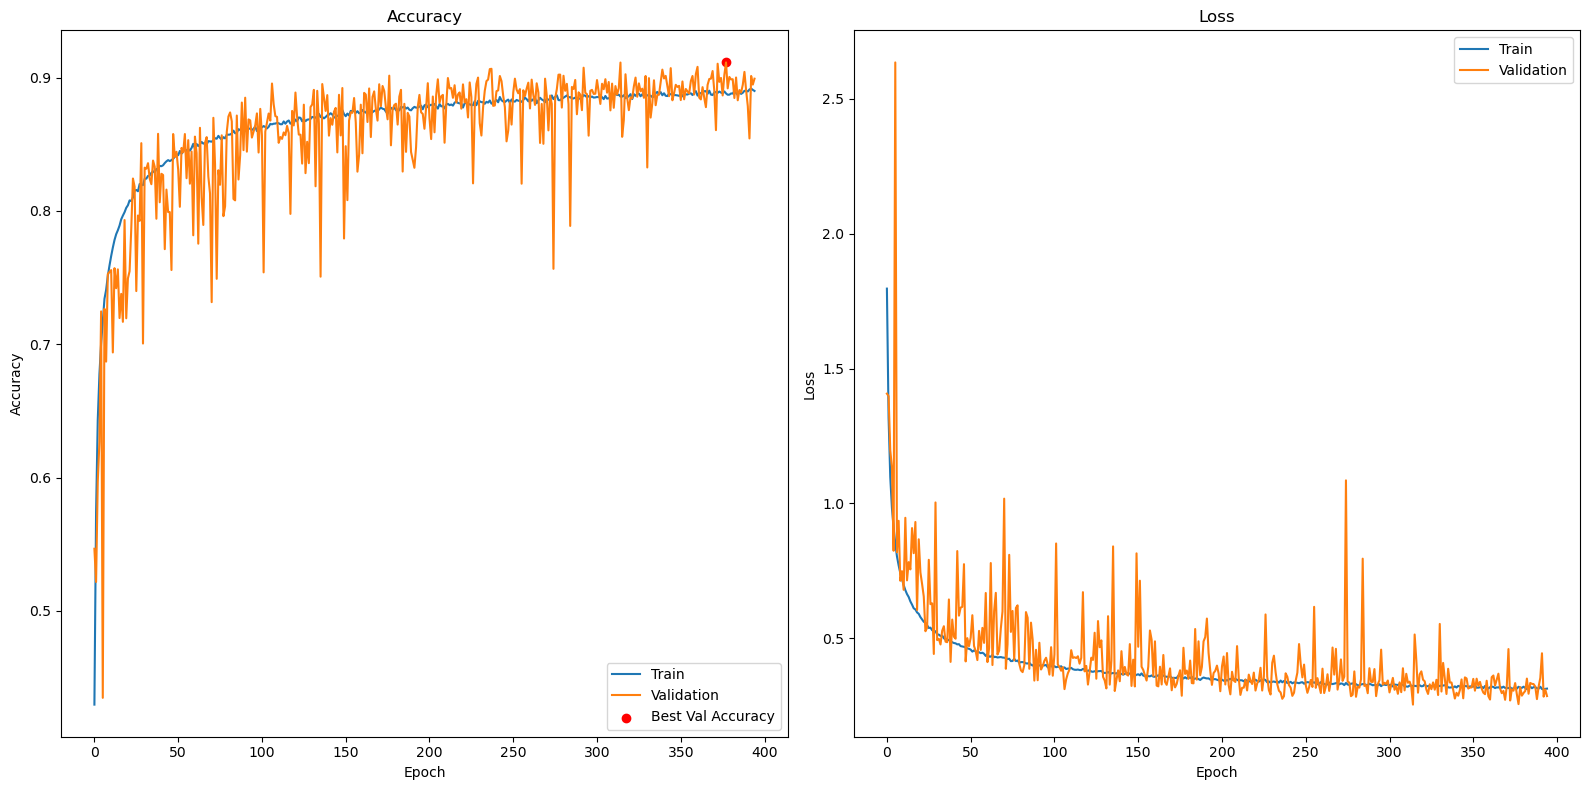

In [8]:
# History plot
log_df = pd.read_csv('training_model_stem_GAP_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

216/216 [==============================] - 1s 3ms/step


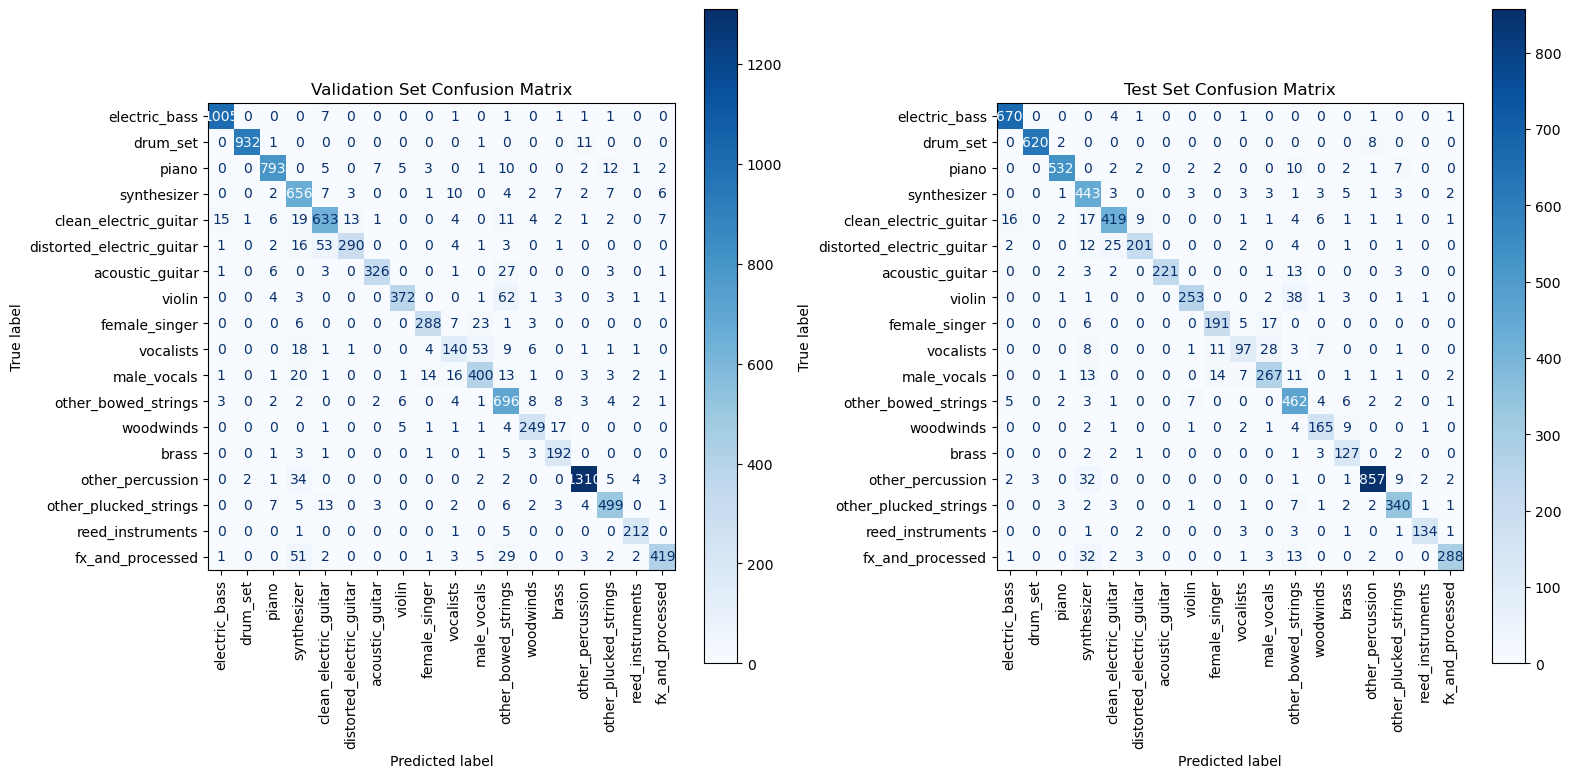

In [9]:
model.load_weights('best_model_stem_GAP_cqt.h5')

# Predict class probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
# For classification report
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.98      0.99      0.98      1017
                 drum_set       1.00      0.99      0.99       945
                    piano       0.96      0.94      0.95       841
              synthesizer       0.79      0.93      0.85       707
    clean_electric_guitar       0.87      0.88      0.88       719
distorted_electric_guitar       0.94      0.78      0.86       371
          acoustic_guitar       0.96      0.89      0.92       368
                   violin       0.96      0.82      0.89       451
            female_singer       0.92      0.88      0.90       328
                vocalists       0.72      0.60      0.65       235
              male_vocals       0.82      0.84      0.83       477
      other_bowed_strings       0.78      0.94      0.85       742
                woodwinds       0.89      0.89      0.89       279
                    brass       0.82      0.93      0.87     

# Model 5: from CQT to MEL

In [7]:
# Load pre-processed data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_mel.npy'))  # or cqt
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

Loaded data: (68879, 96, 130)


In [8]:
# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

#We normalize everything based on this
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

In [9]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')  
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128       
 hNormalization)                                                 
                                                        

In [10]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_GAP_mel.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_GAP_mel.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/500
1615/1615 [==============================] - ETA: 0s - loss: 1.6709 - accuracy: 0.4598
Epoch 1: val_accuracy improved from -inf to 0.58314, saving model to best_model_stem_GAP_mel.h5
1615/1615 [==============================] - 21s 9ms/step - loss: 1.6709 - accuracy: 0.4598 - val_loss: 1.2661 - val_accuracy: 0.5831
Epoch 2/500
1615/1615 [==============================] - ETA: 0s - loss: 1.1451 - accuracy: 0.6156
Epoch 2: val_accuracy improved from 0.58314 to 0.69270, saving model to best_model_stem_GAP_mel.h5
1615/1615 [==============================] - 15s 9ms/step - loss: 1.1451 - accuracy: 0.6156 - val_loss: 0.9134 - val_accuracy: 0.6927
Epoch 3/500
1608/1615 [============================>.] - ETA: 0s - loss: 0.9508 - accuracy: 0.6824
Epoch 3: val_accuracy did not improve from 0.69270
1615/1615 [==============================] - 15s 9ms/step - loss: 0.9512 - accuracy: 0.6821 - val_loss: 1.0928 - val_accuracy: 0.6348
Epoch 4/500
1611/1615 [============================>.] 

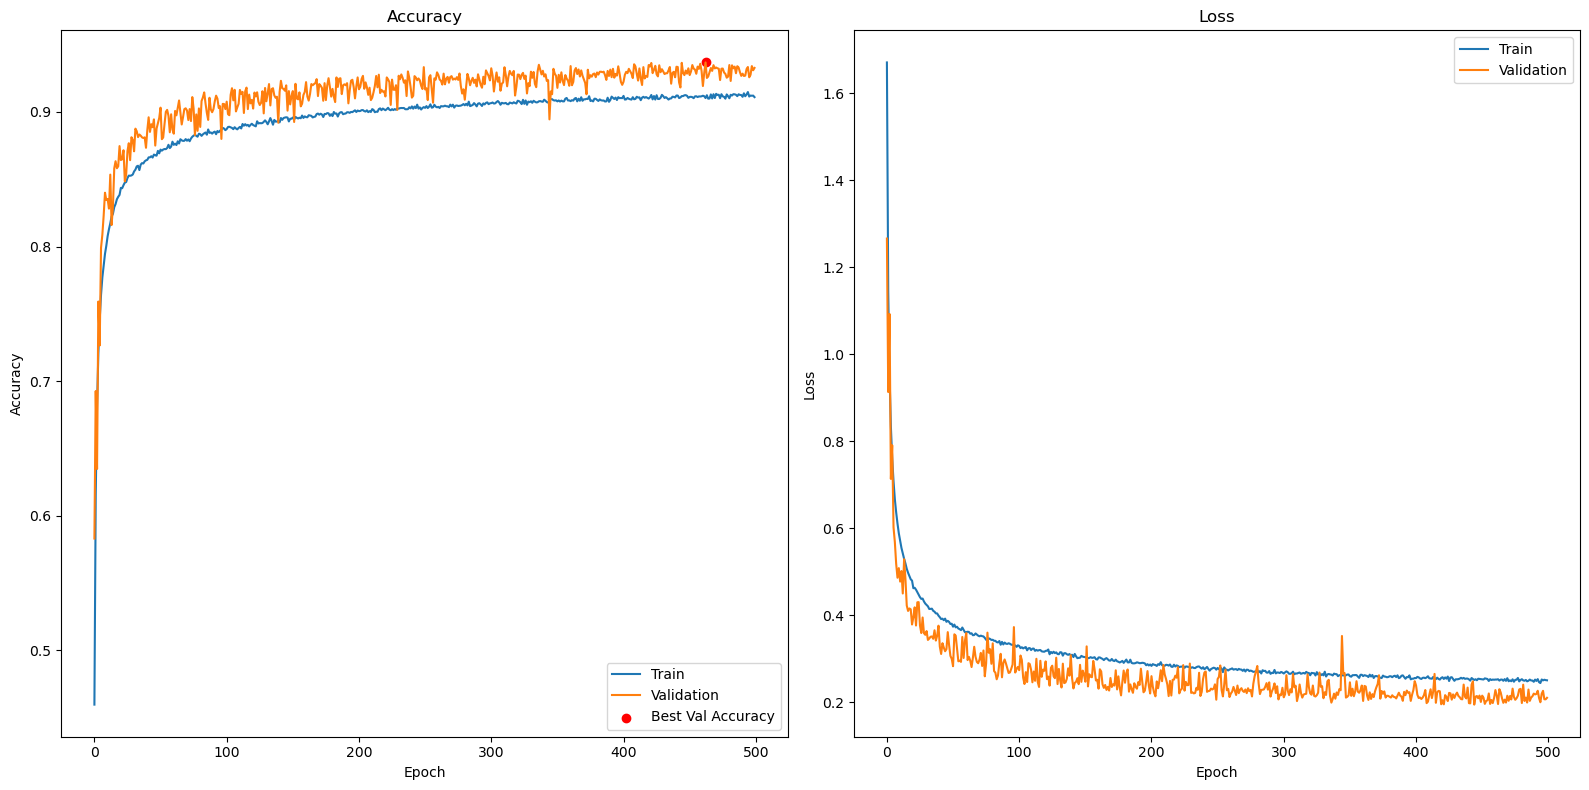

In [11]:
# History plot
log_df = pd.read_csv('training_model_stem_GAP_mel.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

216/216 [==============================] - 0s 2ms/step


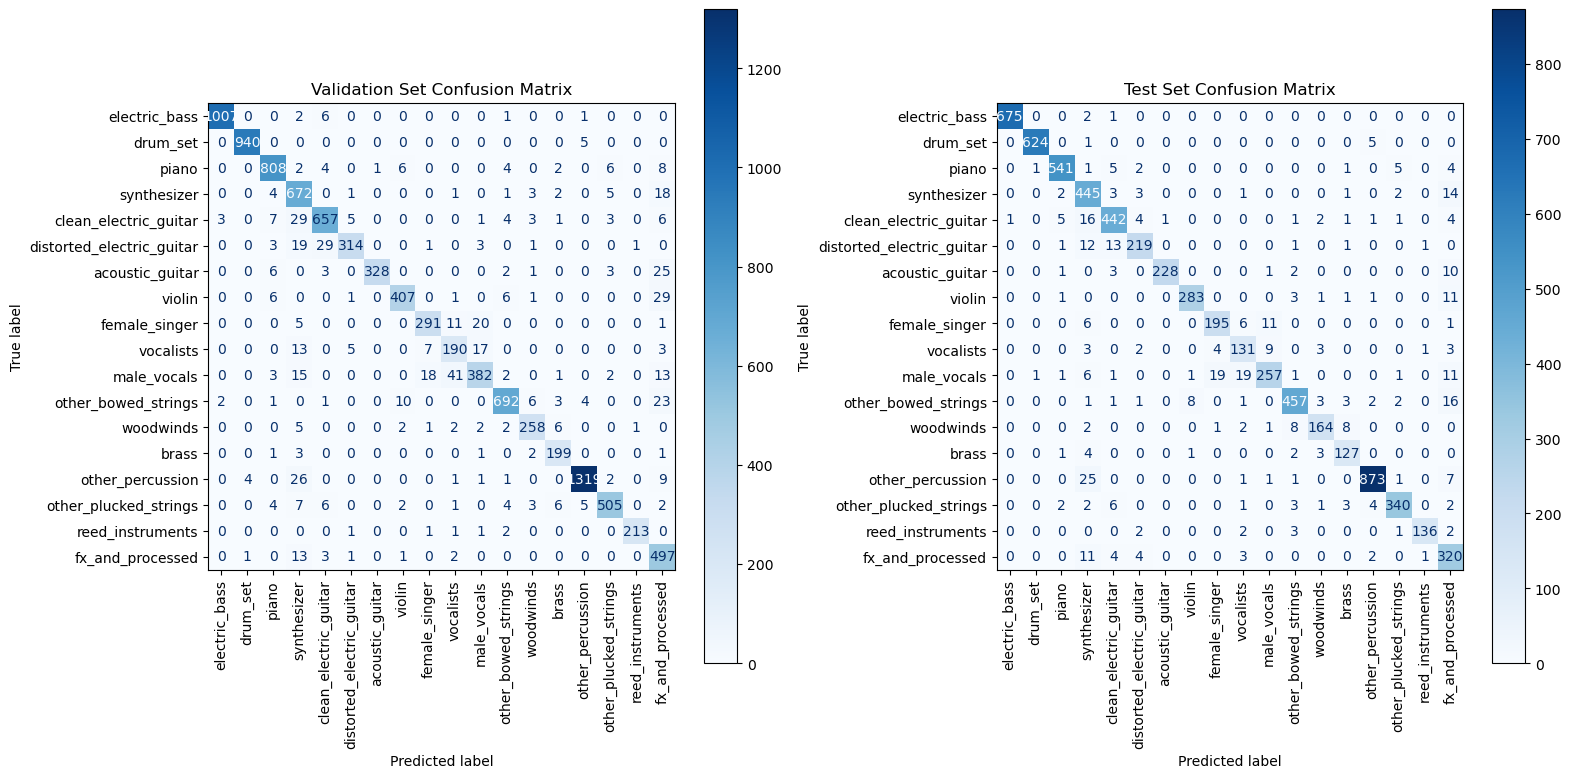

In [12]:
model.load_weights('best_model_stem_GAP_mel.h5')

# Predict class probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
# For classification report
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       1.00      0.99      0.99      1017
                 drum_set       0.99      0.99      0.99       945
                    piano       0.96      0.96      0.96       841
              synthesizer       0.83      0.95      0.89       707
    clean_electric_guitar       0.93      0.91      0.92       719
distorted_electric_guitar       0.96      0.85      0.90       371
          acoustic_guitar       1.00      0.89      0.94       368
                   violin       0.95      0.90      0.93       451
            female_singer       0.91      0.89      0.90       328
                vocalists       0.76      0.81      0.78       235
              male_vocals       0.89      0.80      0.84       477
      other_bowed_strings       0.96      0.93      0.95       742
                woodwinds       0.93      0.92      0.93       279
                    brass       0.90      0.96      0.93     

# Cleaning classes

In [7]:
X = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

#More classes can be added if seen apropiate

classes_to_remove = [3, 17]
mask = ~np.isin(y, classes_to_remove)  # Mask to keep only the desired samples

X_filtered = X[mask]
y_filtered = y[mask]

# Create inverse mapping from index to category name
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]
ordered_labels

for idx in sorted(classes_to_remove, reverse=True):
    del ordered_labels[idx]


old_to_new = {}
new_idx = 0
for i in range(18):  # original class range
    if i not in classes_to_remove:
        old_to_new[i] = new_idx
        new_idx += 1

# Apply the mapping to y_filtered
y_filtered = np.array([old_to_new[old_label] for old_label in y_filtered])

In [8]:
# Clases a fusionar (por índice después de la limpieza)
classes_to_merge = [7,8,9]  # ejemplo, ajusta según tus datos
new_class_name = 'Voices'

# Actualizar etiquetas y nombres
# Paso 1: Crear mapping de índices originales a nombres de clase (ya depurado)
idx_to_category = {i: label for i, label in enumerate(ordered_labels)}

# Paso 2: Crear nuevo nombre de clases fusionadas
# Mantener solo un nombre representativo
merged_label_set = set(classes_to_merge)
merged_name = new_class_name

# Paso 3: Reasignar las etiquetas fusionadas en y_filtered
y_merged = y_filtered.copy()
for idx in merged_label_set:
    y_merged[y_merged == idx] = classes_to_merge[0]  # Asigna todos al primero por simplicidad

# Paso 4: Eliminar los índices sobrantes en orden inverso para no romper el orden
# (menos el primero de la fusión, que es donde caerán todos)
for idx in sorted(classes_to_merge[1:], reverse=True):
    del idx_to_category[idx]

# Paso 5: Cambiar el nombre del índice que se conserva
idx_to_category[classes_to_merge[0]] = merged_name

# Paso 6: Reordenar índices
old_to_new = {}
new_labels = []
new_idx = 0
for old_idx in sorted(idx_to_category.keys()):
    old_to_new[old_idx] = new_idx
    new_labels.append(idx_to_category[old_idx])
    new_idx += 1

# Paso 7: Aplicar el nuevo mapeo a las etiquetas
y_final = np.array([old_to_new[old_label] for old_label in y_merged])
X_final = X_filtered  # No cambia

# Listado final de clases
ordered_labels = new_labels

# Verificación
print("Etiquetas finales:", ordered_labels)
print("Shape X_final:", X_final.shape)
print("Shape y_final:", np.shape(y_final))

Etiquetas finales: ['electric_bass', 'drum_set', 'piano', 'clean_electric_guitar', 'distorted_electric_guitar', 'acoustic_guitar', 'violin', 'Voices', 'other_bowed_strings', 'woodwinds', 'brass', 'other_percussion', 'other_plucked_strings', 'reed_instruments']
Shape X_final: (60716, 96, 130)
Shape y_final: (60716,)



Class distribution in the filtered dataset:
  other_percussion: 9085 samples (15.0%)
  Voices: 6935 samples (11.4%)
  electric_bass: 6781 samples (11.2%)
  drum_set: 6300 samples (10.4%)
  piano: 5604 samples (9.2%)
  other_bowed_strings: 4946 samples (8.1%)
  clean_electric_guitar: 4790 samples (7.9%)
  other_plucked_strings: 3635 samples (6.0%)
  violin: 3010 samples (5.0%)
  distorted_electric_guitar: 2475 samples (4.1%)
  acoustic_guitar: 2452 samples (4.0%)
  woodwinds: 1860 samples (3.1%)
  reed_instruments: 1460 samples (2.4%)
  brass: 1383 samples (2.3%)


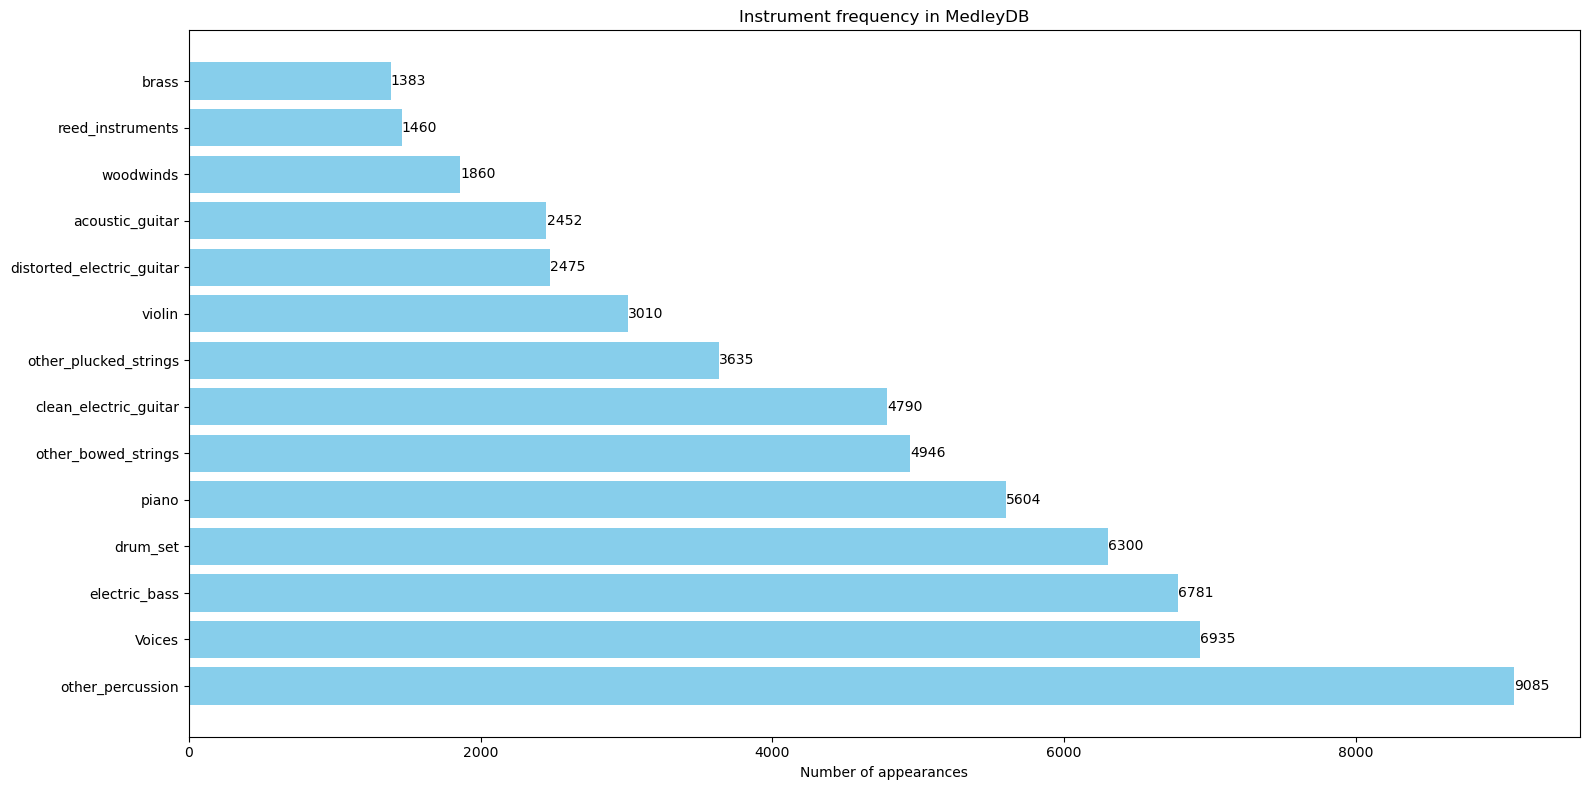


Dataset dimensions:
  Filtered data: (60716, 96, 130)
  Total number of samples: 60716
  Number of categories: 14


In [9]:
# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y_final, return_counts=True)

# Create a dictionary: {category_name: count}
category_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = ordered_labels[idx]
    category_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the filtered dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count / len(y_filtered) * 100:.1f}%)")

# Plot histogram
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Dataset summary
print(f"\nDataset dimensions:")
print(f"  Filtered data: {X_filtered.shape}")
print(f"  Total number of samples: {len(y_filtered)}")
print(f"  Number of categories: {len(ordered_labels)}")

In [10]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X_final, y_final, test_size=0.1, random_state=42, stratify=y_final
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

In [11]:
# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# We normalize everything based on this
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

# Model 6: replace Flatten with GlobalAveragePooling2D and decreases to 32

Don't run yet, only after checking the other results.
Consider also trying with mel to compare.

In [12]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')  
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128       
 hNormalization)                                                 
                                                        

In [13]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_small_GAP_mel.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=80)

model_name = 'best_model_stem_small_GAP_mel.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/500
1420/1423 [============================>.] - ETA: 0s - loss: 1.2218 - accuracy: 0.6021
Epoch 1: val_accuracy improved from -inf to 0.69906, saving model to best_model_stem_small_GAP_mel.h5
1423/1423 [==============================] - 21s 11ms/step - loss: 1.2210 - accuracy: 0.6023 - val_loss: 0.8931 - val_accuracy: 0.6991
Epoch 2/500
1421/1423 [============================>.] - ETA: 0s - loss: 0.6967 - accuracy: 0.7718
Epoch 2: val_accuracy improved from 0.69906 to 0.84080, saving model to best_model_stem_small_GAP_mel.h5
1423/1423 [==============================] - 15s 10ms/step - loss: 0.6966 - accuracy: 0.7718 - val_loss: 0.4721 - val_accuracy: 0.8408
Epoch 3/500
1420/1423 [============================>.] - ETA: 0s - loss: 0.5336 - accuracy: 0.8232
Epoch 3: val_accuracy did not improve from 0.84080
1423/1423 [==============================] - 14s 10ms/step - loss: 0.5334 - accuracy: 0.8232 - val_loss: 0.4828 - val_accuracy: 0.8301
Epoch 4/500
1423/1423 [=================

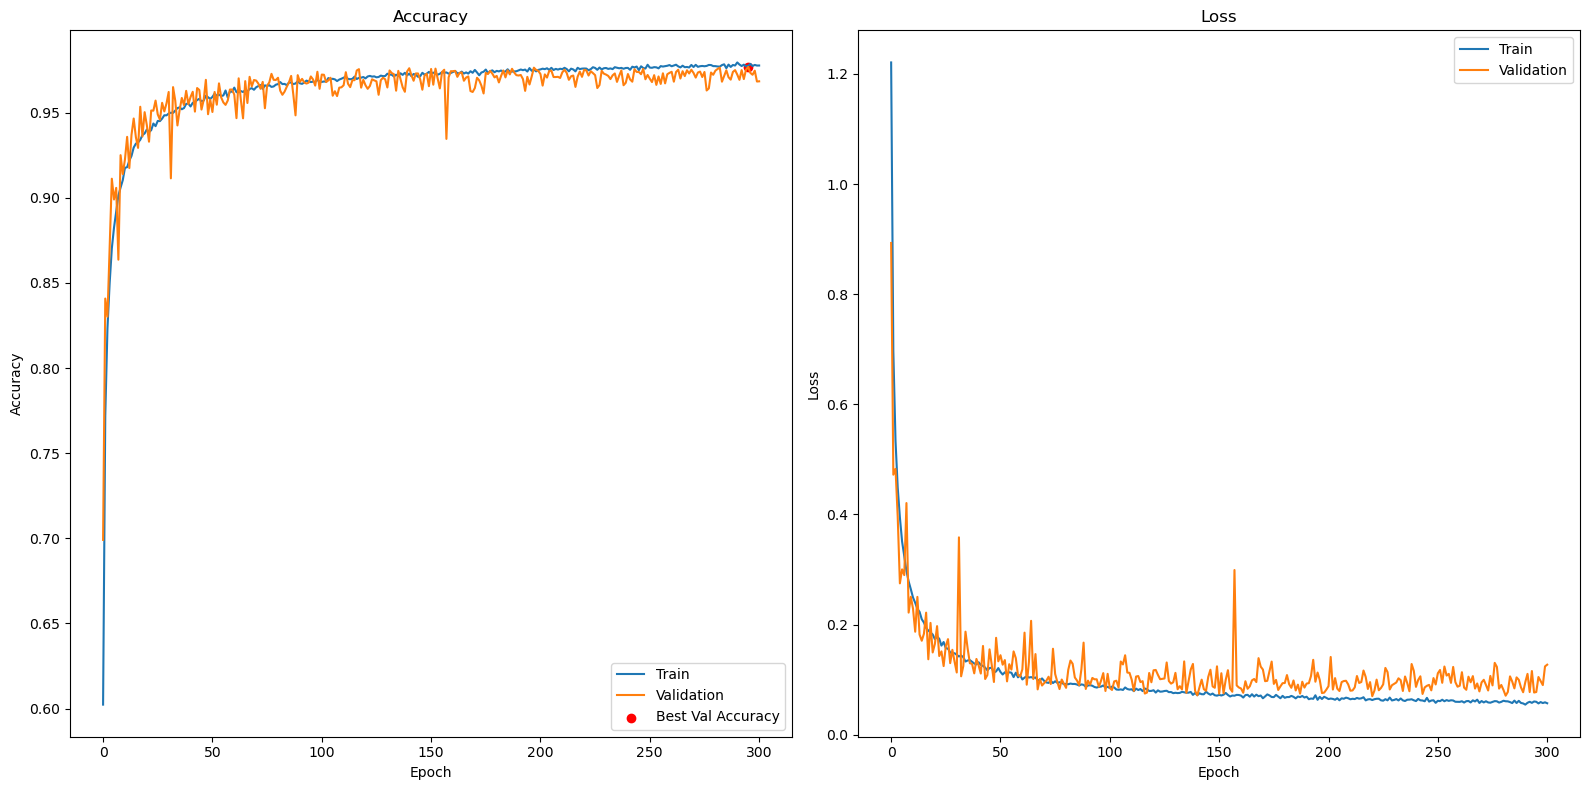

In [14]:
# History plot
log_df = pd.read_csv('training_model_stem_small_GAP_mel.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

190/190 [==============================] - 0s 2ms/step


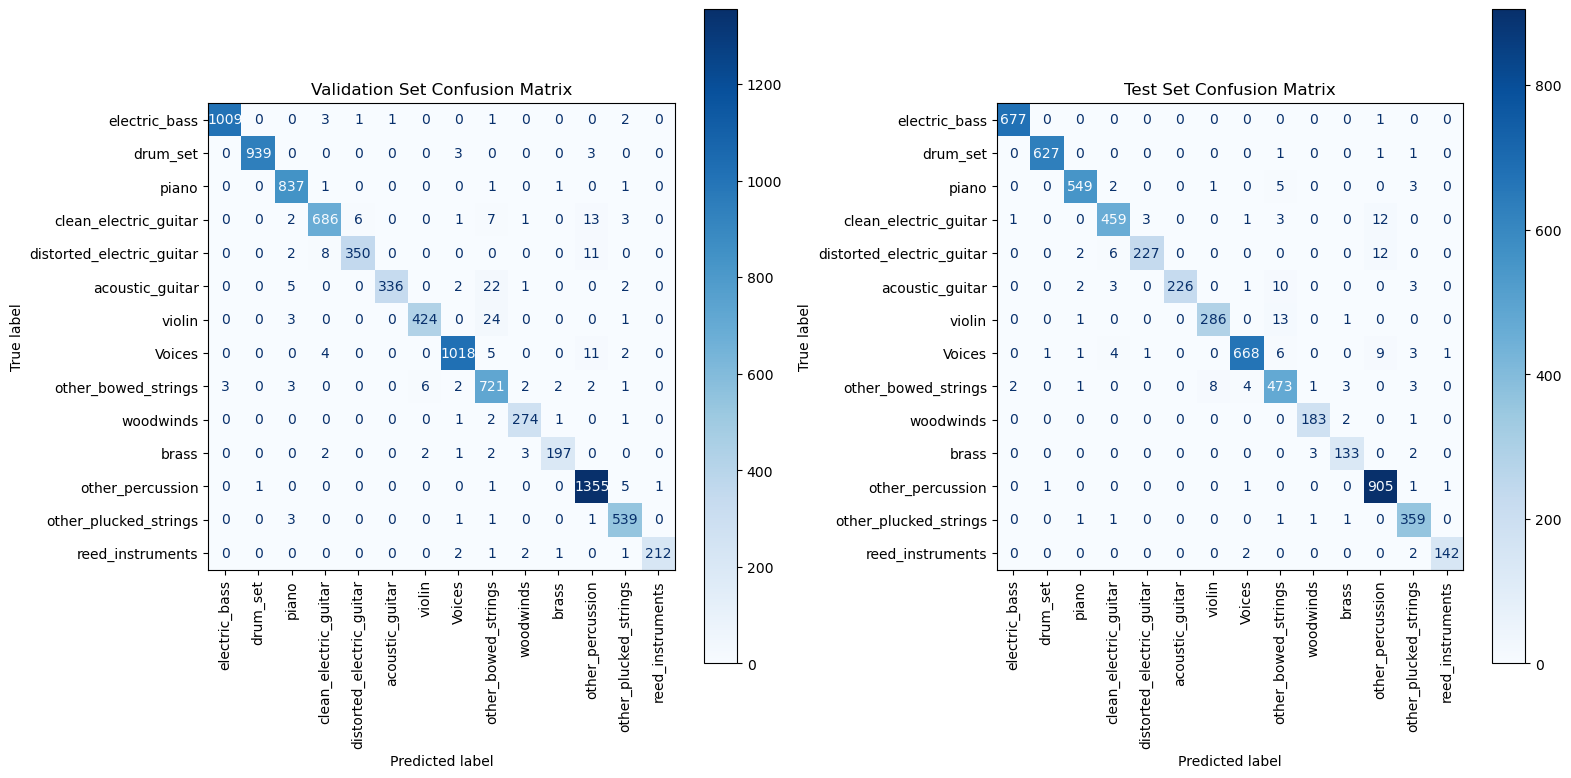

In [15]:
model.load_weights('best_model_stem_small_GAP_mel.h5')
# Predict class probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
# For classification report
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       1.00      0.99      0.99      1017
                 drum_set       1.00      0.99      1.00       945
                    piano       0.98      1.00      0.99       841
    clean_electric_guitar       0.97      0.95      0.96       719
distorted_electric_guitar       0.98      0.94      0.96       371
          acoustic_guitar       1.00      0.91      0.95       368
                   violin       0.98      0.94      0.96       452
                   Voices       0.99      0.98      0.98      1040
      other_bowed_strings       0.91      0.97      0.94       742
                woodwinds       0.97      0.98      0.98       279
                    brass       0.98      0.95      0.96       207
         other_percussion       0.97      0.99      0.98      1363
    other_plucked_strings       0.97      0.99      0.98       545
         reed_instruments       1.00      0.97      0.98     